In [ ]:

!pip install -q timm torchmetrics pytorch-grad-cam

import torch, torchvision
print("torch", torch.__version__, "cuda:", torch.cuda.is_available())


ERROR: Could not find a version that satisfies the requirement pytorch-grad-cam (from versions: none)
ERROR: No matching distribution found for pytorch-grad-cam
torch 2.8.0+cu126 cuda: True


In [ ]:

from google.colab import drive
drive.mount('/content/drive')
# e.g. put your metadata.csv and images under /content/drive/MyDrive/covid_project/


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import re
import numpy as np

file_path = "/content/drive/MyDrive/covidproject/metadata.csv"
df = pd.read_csv(file_path)

df['finding'] = df['finding'].astype(str).str.strip()

def clean_finding(x):
    x_low = x.lower()
    if "covid" in x_low:
        return 1
    elif "todo" in x_low or "no finding" in x_low:
        return None
    else:
        return 0

df['finding'] = df['finding'].apply(clean_finding)
df = df.dropna(subset=['finding'])

# Handle 'age' column
if 'age' in df.columns:
    median_age = df['age'].median()
    df['age'] = df['age'].fillna(median_age)
else:
    median_age = None

# Handle 'sex' column
if 'sex' in df.columns:
    mode_sex = df['sex'].mode()[0]
    df['sex'] = df['sex'].fillna(mode_sex)
else:
    mode_sex = None

# Handle 'RT_PCR_positive' column
if 'RT_PCR_positive' in df.columns:
    df['RT_PCR_positive'] = df['RT_PCR_positive'].fillna(df['RT_PCR_positive'].mode()[0])

# --- NEW SECTION: Clean 'view' column ---
if 'view' in df.columns:
    df['view'] = df['view'].astype(str).str.lower().str.strip()

    def clean_view(x):
        if 'pa' in x:
            return 'PA'
        elif 'ap' in x:
            return 'AP'
        elif 'axial' in x:
            return 'Axial'
        elif 'lateral' in x:
            return 'Lateral'
        elif 'portable' in x:
            return 'Portable'
        else:
            return 'Unknown'

    df['view'] = df['view'].apply(clean_view)

    # Remove Portable and Unknown views
    df = df[~df['view'].isin(['Portable', 'Unknown'])]

# Ensure patientid exists
if 'patientid' not in df.columns:
    raise ValueError("❌ 'patientid' column missing")

# Convert to string and strip spaces
df['patientid'] = df['patientid'].astype(str).str.strip()

# Remove accidental quotes, weird chars (optional)
df['patientid'] = df['patientid'].str.replace(r'[^A-Za-z0-9_-]', '', regex=True)

# Replace missing IDs (addressed FutureWarning)
df['patientid'] = df['patientid'].replace(['','nan','NaN','None'], pd.NA)

# Drop rows with no patient ID (best practice)
df = df.dropna(subset=['patientid'])

# Ensure patientid exists
df['patientid'] = df['patientid'].astype(str).str.strip()

# Remove weird characters, keep alphanumeric only
df['patientid'] = df['patientid'].apply(lambda x: re.sub(r'[^A-Za-z0-9]', '', x))

# Replace empty IDs with unique generated ones
df['patientid'] = df['patientid'].replace('', np.nan)
df['patientid'] = df['patientid'].fillna(pd.Series('PID_' + df.index.astype(str), index=df.index))

# Save cleaned file
output_path = "/content/cleaned_metadata.csv"
df.to_csv(output_path, index=False)

print("✅ Cleaned and imputed dataset saved at:", output_path)
if median_age is not None:
    print(f"Median age used: {median_age}")
if mode_sex is not None:
    print(f"Mode sex used: {mode_sex}")
if 'view' in df.columns:
    print("Unique view types after cleaning:", df['view'].unique())

print("\nPreview:")
print(df.head())

✅ Cleaned and imputed dataset saved at: /content/cleaned_metadata.csv
Median age used: 55.0
Mode sex used: M
Unique view types after cleaning: ['PA' 'AP' 'Axial']

Preview:
  patientid  offset sex   age  finding RT_PCR_positive survival intubated  \
0         2     0.0   M  65.0      1.0               Y        Y         N   
1         2     3.0   M  65.0      1.0               Y        Y         N   
2         2     5.0   M  65.0      1.0               Y        Y         N   
3         2     6.0   M  65.0      1.0               Y        Y         N   
4         4     0.0   F  52.0      1.0               Y      NaN         N   

  intubation_present went_icu  ...       date  \
0                  N        N  ...  22-Jan-20   
1                  N        N  ...  25-Jan-20   
2                  N        N  ...  27-Jan-20   
3                  N        N  ...  28-Jan-20   
4                  N        N  ...  25-Jan-20   

                                            location  folder  \
0    

In [54]:
# --- Stratified Patient-level 70/15/15 Split with offset_days computation ---

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import warnings

# Load your cleaned dataset
df = pd.read_csv("/content/cleaned_metadata.csv")
print("Loaded cleaned dataset:", df.shape)

# --- Add image_path column (from filename) ---
# This is crucial for the Dataset class to find image files
if 'filename' in df.columns:
    df['image_path'] = df['filename']
else:
    raise ValueError("❌ 'filename' column missing from the metadata. Cannot create 'image_path'.")

# Columns (change if needed)
PATIENT_COL = "patientid"
LABEL_COL   = "finding"      # 1 = COVID, 0 = Non-COVID
OUT_DIR     = "/content"
POSSIBLE_DATE_COLS = [
    "study_date", "exam_date", "acquisition_date",
    "StudyDate", "Date", "study_date_time", "StudyTime"
]

# --- Check patient column ---
if PATIENT_COL not in df.columns:
    raise ValueError(f"❌ Column '{PATIENT_COL}' not found.")

# --- Create patient-level label (majority label per patient) ---
patient_label_df = (
    df.groupby(PATIENT_COL)[LABEL_COL]
      .agg(lambda x: x.value_counts().index[0])
      .reset_index()
      .rename(columns={LABEL_COL: "patient_label"})
)
print("Unique patients:", len(patient_label_df))
print("Label distribution:")
print(patient_label_df["patient_label"].value_counts())

# --- Patient-level stratified split 70/15/15 ---
train_pat, temp_pat = train_test_split(
    patient_label_df,
    train_size=0.70,
    stratify=patient_label_df["patient_label"],
    random_state=42
)
val_pat, test_pat = train_test_split(
    temp_pat,
    train_size=0.50,  # 50/50 of remaining 30% = 15% each
    stratify=temp_pat["patient_label"],
    random_state=42
)

# --- Map patients to image rows ---
train_df = df[df[PATIENT_COL].isin(train_pat[PATIENT_COL])]
val_df   = df[df[PATIENT_COL].isin(val_pat[PATIENT_COL])]
test_df  = df[df[PATIENT_COL].isin(test_pat[PATIENT_COL])]

print(f"\n✅ Split done:\nTrain: {len(train_df)} images ({train_df[PATIENT_COL].nunique()} patients)\n"
      f"Val: {len(val_df)} images ({val_df[PATIENT_COL].nunique()} patients)\n"
      f"Test: {len(test_df)} images ({test_df[PATIENT_COL].nunique()} patients)")

# --- Compute offset_days if a date column exists ---
date_col = None
for c in POSSIBLE_DATE_COLS:
    if c in df.columns:
        date_col = c
        break

if date_col:
    print("\n Using date column for offset:", date_col)
    df["parsed_date"] = pd.to_datetime(df[date_col], errors="coerce")

    # Earliest date per patient
    patient_start = (
        df.groupby(PATIENT_COL)["parsed_date"]
          .min()
          .reset_index()
          .rename(columns={"parsed_date": "patient_start_date"})
    )
    df = df.merge(patient_start, on=PATIENT_COL, how="left")

    # Offset (days since first study)
    df["offset_days"] = (df["parsed_date"] - df["patient_start_date"]).dt.days
else:
    warnings.warn(" No date column found. 'offset_days' not computed.")
    df["offset_days"] = np.nan

# --- Reapply patient split on df with offset ---
train_df = df[df[PATIENT_COL].isin(train_pat[PATIENT_COL])]
val_df   = df[df[PATIENT_COL].isin(val_pat[PATIENT_COL])]
test_df  = df[df[PATIENT_COL].isin(test_pat[PATIENT_COL])]

# --- Save CSVs ---
train_path = f"{OUT_DIR}/train.csv"
val_path   = f"{OUT_DIR}/val.csv"
test_path  = f"{OUT_DIR}/test.csv"
train_df.to_csv(train_path, index=False)
val_df.to_csv(val_path, index=False)
test_df.to_csv(test_path, index=False)

print("\n Saved split CSVs:")
print(train_path)
print(val_path)
print(test_path)

# --- Sanity check for leakage ---
train_pats = set(train_df[PATIENT_COL])
val_pats   = set(val_df[PATIENT_COL])
test_pats  = set(test_df[PATIENT_COL])

assert train_pats.isdisjoint(val_pats)
assert train_pats.isdisjoint(test_pats)
assert val_pats.isdisjoint(test_pats)

print("\n No patient leakage detected!")

# --- Summary ---
print("\nSummary:")
print(f"Total images: {len(df)}")
print(f"Train: {len(train_df)} ({len(train_pats)} patients)")
print(f"Val:   {len(val_df)} ({len(val_pats)} patients)")
print(f"Test:  {len(test_df)} ({len(test_pats)} patients)")
if "offset_days" in df.columns:
    print(f"Offset range: {df['offset_days'].min()} to {df['offset_days'].max()} days")

Loaded cleaned dataset: (745, 30)
Unique patients: 446
Label distribution:
patient_label
1.0    321
0.0    125
Name: count, dtype: int64

✅ Split done:
Train: 527 images (312 patients)
Val: 118 images (67 patients)
Test: 100 images (67 patients)

 Saved split CSVs:
/content/train.csv
/content/val.csv
/content/test.csv

 No patient leakage detected!

Summary:
Total images: 745
Train: 527 (312 patients)
Val:   118 (67 patients)
Test:  100 (67 patients)
Offset range: nan to nan days


/tmp/ipython-input-3437618823.py:89: UserWarning:  No date column found. 'offset_days' not computed.
  warnings.warn(" No date column found. 'offset_days' not computed.")


In [55]:
import random
from PIL import Image
import torchvision.transforms as T

class RandomResizeShorter:
    def __init__(self, min_size=256, max_size=480, interpolation=Image.BILINEAR):
        self.min_size = min_size
        self.max_size = max_size
        self.interpolation = interpolation
    def __call__(self, img):
        short = random.randint(self.min_size, self.max_size)
        w, h = img.size
        if w < h:
            new_w = short
            new_h = int(round(h * short / w))
        else:
            new_h = short
            new_w = int(round(w * short / h))
        return img.resize((new_w, new_h), self.interpolation)

train_transforms = T.Compose([
    T.Resize((224, 224)),
    T.RandomResizedCrop(224, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(20),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    T.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    T.RandomGrayscale(p=0.1),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225])
])


val_transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225])
])

print("Transforms created.")


Transforms created.


In [56]:
# Cell F.1 — Dataset class (image + age + sex + view + offset)
import os, torch, numpy as np, pandas as pd
from torch.utils.data import Dataset
from PIL import Image

class XRayMultimodalDataset(Dataset):
    def __init__(self, csv_file, root_dir='', transform=None):
        self.df = pd.read_csv(csv_file)
        self.root = root_dir
        self.transform = transform

        # normalize column names to lowercase
        self.df.columns = [c.lower() for c in self.df.columns]

        # required checks
        required = ['image_path','finding','patientid']
        for r in required:
            if r not in self.df.columns:
                raise ValueError(f"Required column '{r}' missing in {csv_file}")

        # build categorical maps
        # sex: map known values to 0/1, unknown -> 2
        self.sex_map = {'m':0, 'male':0, 'f':1, 'female':1}
        # view map from dataset unique values; unknown will map to -1
        self.view_vals = sorted(self.df['view'].dropna().unique()) if 'view' in self.df.columns else []
        self.view_map = {v:i for i,v in enumerate(self.view_vals)}

        # numeric stats for normalization
        if 'age' in self.df.columns:
            self.age_mean = float(self.df['age'].mean())
            self.age_std  = float(self.df['age'].std()) if float(self.df['age'].std())>0 else 1.0
        else:
            self.age_mean = 0.0
            self.age_std = 1.0

        # If offset_days not present, create column of zeros for consistency
        if 'offset_days' not in self.df.columns:
            self.df['offset_days'] = 0.0

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        # image
        img_path = os.path.join(self.root, str(row['image_path']))
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)

        # label
        label = int(row['finding'])

        # age (normalize)
        age_val = row['age'] if 'age' in row and not pd.isna(row['age']) else self.age_mean
        age = (float(age_val) - self.age_mean) / (self.age_std + 1e-8)
        age = torch.tensor([age], dtype=torch.float32)

        # sex index
        sex_raw = str(row['sex']).strip().lower() if 'sex' in row and not pd.isna(row['sex']) else 'unknown'
        sex_idx = self.sex_map.get(sex_raw, 2)
        sex_idx = torch.tensor(sex_idx, dtype=torch.long)

        # view label (int) - keep -1 if unknown
        view_raw = row['view'] if 'view' in row and not pd.isna(row['view']) else None
        view_label = self.view_map.get(view_raw, -1)
        view_label = torch.tensor(view_label, dtype=torch.long)

        # offset days numeric
        offset_val = row.get('offset_days', 0.0)
        offset = torch.tensor([0.0 if pd.isna(offset_val) else float(offset_val)], dtype=torch.float32)

        return img, torch.tensor(label, dtype=torch.long), age, sex_idx, view_label, offset


In [57]:
import pandas as pd

for split in ["train", "val", "test"]:
    df = pd.read_csv(f"/content/{split}.csv")

    # Rename column from filename → image_path
    if "filename" in df.columns:
        df = df.rename(columns={"filename": "image_path"})

    df.to_csv(f"/content/{split}.csv", index=False)
    print(f"✅ {split}.csv updated and saved.")


✅ train.csv updated and saved.
✅ val.csv updated and saved.
✅ test.csv updated and saved.


In [39]:
import pandas as pd
pd.read_csv("/content/train.csv").head()


,patientid,offset,sex,age,finding,RT_PCR_positive,survival,intubated,intubation_present,went_icu,...,folder,image_path,doi,url,license,clinical_notes,other_notes,Unnamed: 29,image_path.1,offset_days
0,2,0.0,M,65.0,1.0,Y,Y,N,N,N,...,images,auntminnie-a-2020_01_28_23_51_6665_2020_01_28_...,10.1056/nejmc2001272,https://www.nejm.org/doi/full/10.1056/NEJMc200...,NaN,"On January 22, 2020, a 65-year-old man with a ...",NaN,NaN,auntminnie-a-2020_01_28_23_51_6665_2020_01_28_...,NaN
1,2,3.0,M,65.0,1.0,Y,Y,N,N,N,...,images,auntminnie-b-2020_01_28_23_51_6665_2020_01_28_...,10.1056/nejmc2001272,https://www.nejm.org/doi/full/10.1056/NEJMc200...,NaN,"On January 22, 2020, a 65-year-old man with a ...",NaN,NaN,auntminnie-b-2020_01_28_23_51_6665_2020_01_28_...,NaN
2,2,5.0,M,65.0,1.0,Y,Y,N,N,N,...,images,auntminnie-c-2020_01_28_23_51_6665_2020_01_28_...,10.1056/nejmc2001272,https://www.nejm.org/doi/full/10.1056/NEJMc200...,NaN,"On January 22, 2020, a 65-year-old man with a ...",NaN,NaN,auntminnie-c-2020_01_28_23_51_6665_2020_01_28_...,NaN
3,2,6.0,M,65.0,1.0,Y,Y,N,N,N,...,images,auntminnie-d-2020_01_28_23_51_6665_2020_01_28_...,10.1056/nejmc2001272,https://www.nejm.org/doi/full/10.1056/NEJMc200...,NaN,"On January 22, 2020, a 65-year-old man with a ...",NaN,NaN,auntminnie-d-2020_01_28_23_51_6665_2020_01_28_...,NaN
4,4,0.0,F,52.0,1.0,Y,NaN,N,N,N,...,images,nejmc2001573_f1a.jpeg,10.1056/NEJMc2001573,https://www.nejm.org/doi/full/10.1056/NEJMc200...,NaN,diffuse infiltrates in the bilateral lower lungs,NaN,NaN,nejmc2001573_f1a.jpeg,NaN


In [58]:
import pandas as pd

df = pd.read_csv("/content/train.csv")
print(df['image_path'].str[-10:].value_counts().head(10))


image_path
jumbo.jpeg    40
dcm.nii.gz    10
_jumbo.jpg     8
HTML-b.png     7
HTML-a.png     7
_lrg-b.png     7
mbo-1.jpeg     6
_lrg-a.png     5
umbo-1.jpg     5
HTML-c.png     4
Name: count, dtype: int64


In [59]:
for split in ["train", "val", "test"]:
    df = pd.read_csv(f"/content/{split}.csv")
    # keep only images ending with .png, .jpg, .jpeg
    df = df[df['image_path'].str.lower().str.endswith(('.png', '.jpg', '.jpeg'))]
    df.to_csv(f"/content/{split}.csv", index=False)
    print(f"✅ Removed non-image files from {split}.csv — now {len(df)} rows")


✅ Removed non-image files from train.csv — now 510 rows
✅ Removed non-image files from val.csv — now 116 rows
✅ Removed non-image files from test.csv — now 98 rows


In [ ]:
import os, pandas as pd

ROOT_DIR = "/content/drive/MyDrive/covidproject/images"
for split in ["train", "val", "test"]:
    df = pd.read_csv(f"/content/{split}.csv")
    missing = [p for p in df['image_path'] if not os.path.exists(os.path.join(ROOT_DIR, p))]
    print(f"{split}: {len(missing)} missing images out of {len(df)}")


train: 0 missing images out of 510
val: 0 missing images out of 116
test: 0 missing images out of 98


In [ ]:
# Cell G.1 — create datasets and dataloaders
from torch.utils.data import DataLoader

ROOT_DIR = "/content/drive/MyDrive/covidproject/images"   # <-- change to your images folder
train_csv = "/content/train.csv"
val_csv   = "/content/val.csv"
test_csv  = "/content/test.csv"

train_ds = XRayMultimodalDataset(train_csv, root_dir=ROOT_DIR, transform=train_transforms)
val_ds   = XRayMultimodalDataset(val_csv,   root_dir=ROOT_DIR, transform=val_transforms)
test_ds  = XRayMultimodalDataset(test_csv,  root_dir=ROOT_DIR, transform=val_transforms)

# Save view_map and sizes for model init and sanity checks
n_views = len(train_ds.view_map)
print("n_views (train):", n_views, "view values:", train_ds.view_vals)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=4, pin_memory=True)

print("Train images:", len(train_ds), "Val images:", len(val_ds), "Test images:", len(test_ds))
print("Example batch shapes (images,label,age,sex,view,offset):")
batch = next(iter(train_loader))
print([b.shape if hasattr(b,'shape') else type(b) for b in batch])


n_views (train): 3 view values: ['AP', 'Axial', 'PA']
Train images: 510 Val images: 116 Test images: 98
Example batch shapes (images,label,age,sex,view,offset):


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


[torch.Size([32, 3, 224, 224]), torch.Size([32]), torch.Size([32, 1]), torch.Size([32]), torch.Size([32]), torch.Size([32, 1])]


In [63]:
# Cell H.1 — model definition
import torch.nn as nn
import torchvision.models as models
import torch

class MultimodalResNet(nn.Module):
    def __init__(self, n_views, tabular_emb_dim=64, pretrained=True):
        super().__init__()
        base = models.resnet50(pretrained=pretrained)
        self.backbone = nn.Sequential(*list(base.children())[:-1])  # (B,2048,1,1)
        self.img_feat_dim = 2048

        # sex embedding + tabular MLP (sex_emb + age + offset)
        self.sex_emb = nn.Embedding(num_embeddings=3, embedding_dim=8)
        self.tab_mlp = nn.Sequential(
            nn.Linear(8 + 2, 64),   # sex_emb(8) + age(1) + offset(1)
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(0.3),
            nn.Linear(64, tabular_emb_dim),
            nn.ReLU()
        )

        # combined classifier
        combined_dim = self.img_feat_dim + tabular_emb_dim
        self.classifier = nn.Sequential(
            nn.Linear(combined_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 1)   # binary logit
        )

        # auxiliary view head
        self.view_head = nn.Sequential(
            nn.Linear(self.img_feat_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, n_views) if n_views>0 else nn.Linear(256, 1)
        )

    def forward(self, img, age, sex_idx, offset):
        x = self.backbone(img)
        x = x.view(x.size(0), -1)  # (B,2048)

        sex_e = self.sex_emb(sex_idx)
        tab = torch.cat([sex_e, age, offset], dim=1)  # (B, 8+1+1)
        tab = self.tab_mlp(tab)  # (B, tabular_emb_dim)

        comb = torch.cat([x, tab], dim=1)
        covid_logit = self.classifier(comb).squeeze(1)
        view_logit = self.view_head(x)
        return covid_logit, view_logit

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = MultimodalResNet(n_views=n_views, pretrained=True).to(device)
print(model)


MultimodalResNet(
  (backbone): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
          (0): C

In [64]:
# Cell I.1 — losses and optimizer
import torch.nn as nn
import torch.optim as optim
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import pandas as pd

# compute pos_weight for BCE using train.csv
y_train = pd.read_csv("/content/train.csv")['finding'].astype(int).values
if len(np.unique(y_train)) > 1:
    cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
    # cw gives weight per class; pos_weight arg expects weight for class 1 relative to 0
    pos_weight = torch.tensor(cw[1], dtype=torch.float32).to(device)
    print("pos_weight:", pos_weight.item())
else:
    pos_weight = None
    print("Only one class in training set; pos_weight not used.")

bce_loss = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
ce_loss  = nn.CrossEntropyLoss()

optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
print("Optimizer and losses created.")


pos_weight: 0.6929348111152649
Optimizer and losses created.


In [65]:
# Cell J.1 — training loop with val AUC monitoring and checkpointing
import numpy as np
from sklearn.metrics import roc_auc_score
import torch

def evaluate(loader, model):
    model.eval()
    all_probs, all_targets = [], []
    with torch.no_grad():
        for img, label, age, sex, view, offset in loader:
            img = img.to(device); label = label.to(device)
            age = age.to(device); sex = sex.to(device); offset = offset.to(device)
            logits, _ = model(img, age, sex, offset)
            probs = torch.sigmoid(logits).cpu().numpy()
            all_probs.extend(probs.tolist())
            all_targets.extend(label.cpu().numpy().tolist())
    try:
        auc = roc_auc_score(all_targets, all_probs)
    except:
        auc = float('nan')
    return auc

EPOCHS = 25
alpha = 0.5  # weight for auxiliary view loss
best_auc = 0.0

for epoch in range(1, EPOCHS+1):
    model.train()
    running_loss = 0.0
    for batch in train_loader:
        img, label, age, sex, view, offset = batch
        img = img.to(device); label = label.to(device)
        age = age.to(device); sex = sex.to(device); view = view.to(device); offset = offset.to(device)

        optimizer.zero_grad()
        covid_logits, view_logits = model(img, age, sex, offset)

        loss_covid = bce_loss(covid_logits, label.float())

        # view loss only for examples with view >=0
        mask = (view >= 0)
        if mask.sum() > 0 and n_views > 0:
            loss_view = ce_loss(view_logits[mask], view[mask])
        else:
            loss_view = torch.tensor(0., device=device)

        loss = loss_covid + alpha * loss_view
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * img.size(0)

    scheduler.step()
    train_auc = evaluate(train_loader, model)
    val_auc = evaluate(val_loader, model)
    avg_loss = running_loss / len(train_ds)
    print(f"Epoch {epoch}/{EPOCHS}  Loss: {avg_loss:.4f}  TrainAUC: {train_auc:.4f}  ValAUC: {val_auc:.4f}")

    if val_auc > best_auc:
        best_auc = val_auc
        torch.save(model.state_dict(), "/content/best_multimodal_resnet.pth")
        print(f"✅ New best model saved (ValAUC={best_auc:.4f})")


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Epoch 1/25  Loss: 0.9790  TrainAUC: 0.6923  ValAUC: 0.7364
✅ New best model saved (ValAUC=0.7364)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Epoch 2/25  Loss: 0.8863  TrainAUC: 0.7698  ValAUC: 0.7432
✅ New best model saved (ValAUC=0.7432)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Epoch 3/25  Loss: 0.7693  TrainAUC: 0.8361  ValAUC: 0.7536
✅ New best model saved (ValAUC=0.7536)


... (40 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Epoch 24/25  Loss: 0.2258  TrainAUC: 0.9939  ValAUC: 0.8806


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Epoch 25/25  Loss: 0.2429  TrainAUC: 0.9914  ValAUC: 0.8784


🔍 Running inference on test set...
✅ Predictions saved to /content/test_predictions.csv

📈 Image-level Test AUC: 0.8602
🏥 Patient-level Test AUC (mean prob): 0.8673

🧾 Confusion Matrix (Patient-level):
[[12  7]
 [ 5 41]]

Precision: 0.854, Recall: 0.891, F1: 0.872


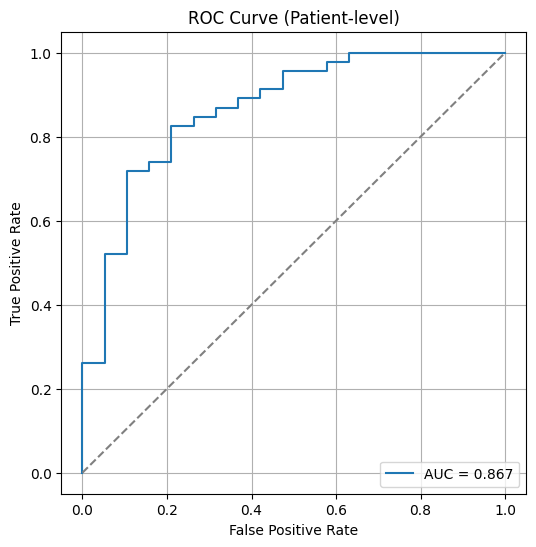

In [66]:
# ===============================
# 📊 FINAL TEST EVALUATION CELL
# ===============================

import torch
import pandas as pd
import numpy as np
import os
from PIL import Image
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_recall_fscore_support, roc_curve
import matplotlib.pyplot as plt

# Load test data
test_df = pd.read_csv("/content/test.csv")

# Load best model
model.load_state_dict(torch.load("/content/best_multimodal_resnet.pth", map_location=device))
model.eval()

rows = []
print("🔍 Running inference on test set...")

for i in range(len(test_df)):
    row = test_df.iloc[i]

    # --- Load and preprocess image ---
    img_path = os.path.join(ROOT_DIR, str(row['image_path']))
    try:
        img_pil = Image.open(img_path).convert('RGB')
    except Exception as e:
        print(f"⚠️ Skipping missing/bad file: {img_path}")
        continue

    img_t = val_transforms(img_pil).unsqueeze(0).to(device)

    # --- Prepare tabular features ---
    # Age
    age_val = row['age'] if not pd.isna(row.get('age', None)) else train_ds.age_mean
    age_t = torch.tensor([[ (age_val - train_ds.age_mean) / (train_ds.age_std + 1e-8) ]], dtype=torch.float32).to(device)

    # Sex
    sex_idx = torch.tensor([ train_ds.sex_map.get(str(row.get('sex','')).strip().lower(), 2) ],
                           dtype=torch.long).to(device)

    # Offset
    offset_val = 0.0 if pd.isna(row.get('offset_days', 0)) else float(row.get('offset_days', 0))
    offset_t = torch.tensor([[offset_val]], dtype=torch.float32).to(device)

    # --- Inference ---
    with torch.no_grad():
        logits, _ = model(img_t, age_t, sex_idx, offset_t)
        prob = torch.sigmoid(logits).item()

    rows.append({
        'patientid': row['patientid'],
        'image_path': row['image_path'],
        'prob': prob,
        'label': int(row['finding'])
    })

# Convert to DataFrame
pred_df = pd.DataFrame(rows)
pred_df.to_csv("/content/test_predictions.csv", index=False)
print("✅ Predictions saved to /content/test_predictions.csv")

# --- Image-level metrics ---
img_auc = roc_auc_score(pred_df['label'], pred_df['prob'])
print(f"\n📈 Image-level Test AUC: {img_auc:.4f}")

# --- Patient-level aggregation ---
pat_df = pred_df.groupby('patientid').agg({
    'prob': 'mean',
    'label': lambda x: int(x.mode()[0])
}).reset_index()

pat_auc = roc_auc_score(pat_df['label'], pat_df['prob'])
print(f"🏥 Patient-level Test AUC (mean prob): {pat_auc:.4f}")

# --- Confusion matrix + F1 metrics (patient-level) ---
threshold = 0.5
preds = (pat_df['prob'] >= threshold).astype(int)
cm = confusion_matrix(pat_df['label'], preds)
prec, recall, f1, _ = precision_recall_fscore_support(pat_df['label'], preds, average='binary')

print("\n🧾 Confusion Matrix (Patient-level):")
print(cm)
print(f"\nPrecision: {prec:.3f}, Recall: {recall:.3f}, F1: {f1:.3f}")

# --- ROC curve plot ---
fpr, tpr, _ = roc_curve(pat_df['label'], pat_df['prob'])
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"AUC = {pat_auc:.3f}")
plt.plot([0,1],[0,1],'--',color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Patient-level)")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()
